# Affine coupling: inverse maps and density checks

**Cambridge MPhil in Data Intensive Science — M2 coursework.**

This notebook checks the mathematical identities needed for a two-dimensional normalising flow. It uses generated two-moons coordinates and an untrained flow, so no checkpoint or external data is required. The checks cover both inverse compositions and compare the analytic inverse log-determinant against autograd and central differences.

The coupling network is `Linear(D, H) → ReLU → Linear(H, 2D)`, with alternating binary masks and a tanh-bounded scale. The class labels are used only for plotting; the density model receives the two coordinates.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd() if (Path.cwd() / 'src' / 'moonflow').is_dir() else Path.cwd().parent
if not (ROOT / 'src' / 'moonflow').is_dir():
    raise RuntimeError('Start Jupyter in the repository root or notebooks directory.')
sys.path.insert(0, str(ROOT / 'src'))

import matplotlib.pyplot as plt
import torch

get_ipython().run_line_magic('matplotlib', 'inline')
torch.set_num_threads(1)
torch.manual_seed(42)
plt.rcParams.update({'font.size': 11, 'figure.dpi': 120})

from moonflow.checks import count_flops, invertibility_errors, log_det_check
from moonflow.data import make_moons_splits
from moonflow.models import NormalisingFlow

splits = make_moons_splits(seed=42)
flow = NormalisingFlow(dim=2, n_layers=6, hidden=64).double().eval()
points = splits['train'].tensor().double()


## The coupling map

For mask $m$, the network takes $m\odot z$ and outputs a scale $s$ and translation $t$, both zero on the fixed coordinates. The map and its inverse are

$$x=m\odot z+(1-m)\odot\left(z\odot e^s+t\right),$$
$$z=m\odot x+(1-m)\odot\left((x-t)\odot e^{-s}\right).$$

The fixed coordinates do not change, so the same network inputs determine $s$ and $t$ in both directions. In the fixed/transformed coordinate ordering, the Jacobian is triangular. Its log-determinant is $\sum_j s_j$ in the forward direction and $-\sum_j s_j$ in the inverse direction.

Stacking coupling layers adds their log-determinants. With $z=f^{-1}(x)$ and a standard-normal base,

$$\log p_X(x)=-\tfrac12\left(\lVert z\rVert^2+D\log(2\pi)\right)+\log\left|\det J_{f^{-1}}(x)\right|.$$

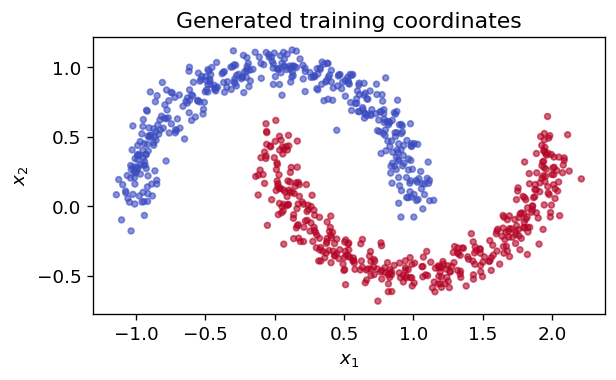

In [2]:
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.scatter(*splits['train'].points.T, c=splits['train'].labels, cmap='coolwarm', s=12, alpha=0.6)
ax.set(xlabel='$x_1$', ylabel='$x_2$', title='Generated training coordinates')
ax.set_aspect('equal')
plt.show()


## Both inverse compositions

The following check uses all 800 training coordinates as test points in both spaces: $f(f^{-1}(x))$ and $f^{-1}(f(z))$. It also checks that the forward and inverse log-determinants cancel at corresponding points. Double precision separates algebraic consistency from float32 round-off.

data_roundtrip_max        : 8.882e-16
latent_roundtrip_max      : 1.110e-15
data_logdet_sum_max       : 4.441e-16
latent_logdet_sum_max     : 6.176e-16


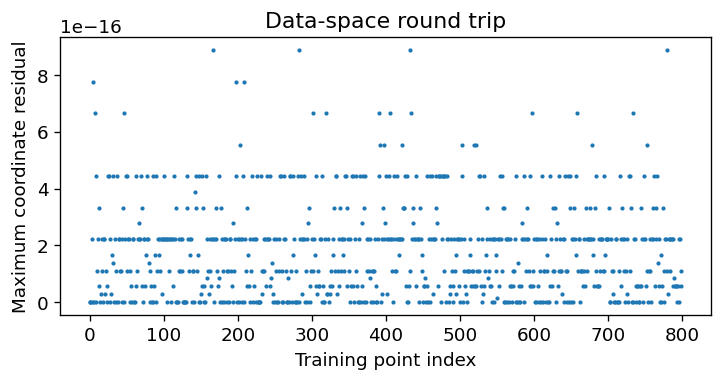

In [3]:
roundtrip = invertibility_errors(flow, points)
for name, value in roundtrip.items():
    print(f'{name:26s}: {value:.3e}')

with torch.no_grad():
    latent, inverse_log_det = flow.inverse(points)
    reconstructed, _ = flow(latent)
    residual = (reconstructed - points).abs().amax(dim=-1)

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(residual.numpy(), '.', markersize=3)
ax.set(xlabel='Training point index', ylabel='Maximum coordinate residual', title='Data-space round trip')
ax.ticklabel_format(axis='y', style='scientific', scilimits=(0, 0))
plt.show()


## Independent Jacobian calculations

For the **first 32 training points**, compare three values of $\log|\det J_{f^{-1}}|$: the analytic sum, a full autograd Jacobian, and a full central-difference Jacobian with step $\varepsilon=10^{-5}$.

Central differences approximate derivatives. Their error depends on step size, precision and proximity to ReLU boundaries; it is not an exact correctness certificate. Autograd evaluates the local derivatives directly. The reported maxima below cover every point in this 32-point subset.

autograd           | points=32 | max=6.661e-16 | mean=1.717e-16
finite_difference  | points=32 | max=3.890e-11 | mean=1.386e-11


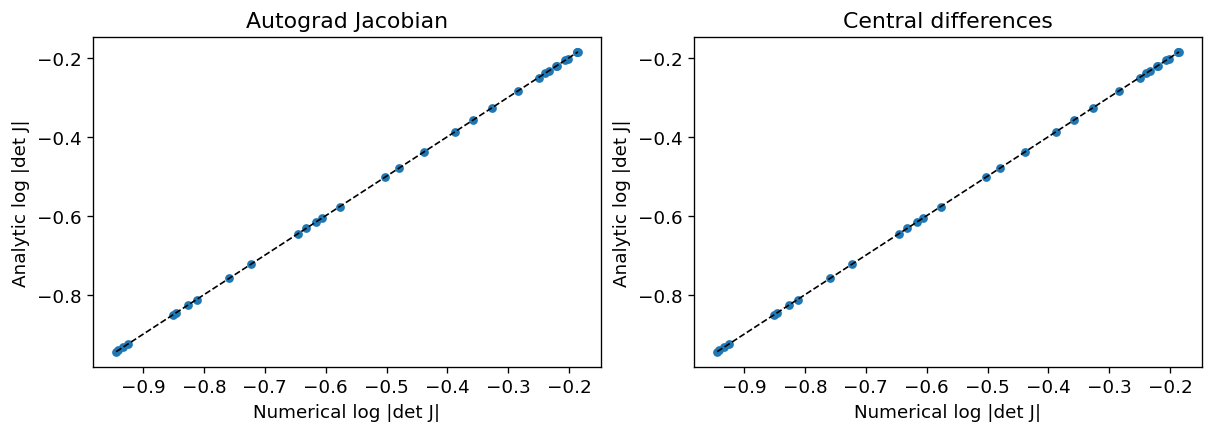

In [4]:
check_points = points[:32]
estimates = log_det_check(flow, check_points, eps=1e-5)
for method in ('autograd', 'finite_difference'):
    error = (estimates[method] - estimates['analytic']).abs()
    print(f'{method:18s} | points={len(check_points)} | max={error.max().item():.3e} | mean={error.mean().item():.3e}')

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)
for ax, method, title in zip(axes, ('autograd', 'finite_difference'), ('Autograd Jacobian', 'Central differences')):
    numerical = estimates[method].numpy()
    analytic = estimates['analytic'].numpy()
    lower, upper = min(numerical.min(), analytic.min()), max(numerical.max(), analytic.max())
    ax.scatter(numerical, analytic, s=18)
    ax.plot([lower, upper], [lower, upper], '--', color='black', linewidth=1)
    ax.set(xlabel='Numerical log |det J|', ylabel='Analytic log |det J|', title=title)
plt.show()


## Density and operation count

The change-of-variables identity can also be evaluated at the same points. The operation count below is an idealised arithmetic estimate: exp, log and tanh cost ten operations each, ReLU costs one, Gaussian log-density evaluation costs twenty, dense elementwise operations are counted, and static mask construction and runtime overhead are excluded. It is not a hardware timing measurement.

In [5]:
with torch.no_grad():
    normal = torch.distributions.Independent(
        torch.distributions.Normal(torch.zeros(2, dtype=torch.float64), torch.ones(2, dtype=torch.float64)), 1,
    )
    expected_log_prob = normal.log_prob(latent) + inverse_log_det
    density_error = (flow.log_prob(points) - expected_log_prob).abs().max().item()

print(f'Gaussian change-of-variables discrepancy: {density_error:.3e}')
print(f'Idealised operations for 800 points: {count_flops(dim=2, n_layers=6, hidden=64, batch_size=800):,}')


Gaussian change-of-variables discrepancy: 8.882e-16
Idealised operations for 800 points: 4,303,200


The numerical checks establish inversion and density consistency at the evaluated points. They do not establish that an untrained flow fits the two-moons distribution. Continue with [density estimation and shear composition](02_density_and_shear.ipynb) for maximum-likelihood training and held-out evaluation.